# Análise Exploratória de Dados (EDA) - Sorriso-MT
Este notebook realiza a análise descritiva e exploratória das variáveis agrícolas, agroclimáticas e das novas features derivadas para o município de Sorriso-MT (safras consolidadas 2015 a 2024).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# Carregar dados limpos e dados com features
df = pd.read_csv("../data/interim/limpo.csv")
df_feat = pd.read_csv("../data/interim/04_dados_com_features.csv")
display(df.head())

,ano,area_plantada_ha,area_colhida_ha,quantidade_produzida_t,rendimento_kg_ha,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,GWETROOT
0,2015,625900.0,619900.0,1951710.0,3148.0,645.49,27.850904,41.79,17.31,61.046274,0.635616
1,2016,620000.0,615000.0,1771200.0,2880.0,1147.75,26.832432,39.57,15.78,66.810902,0.658962
2,2017,620000.0,620000.0,2157600.0,3480.0,1561.12,25.576301,39.86,12.24,74.063096,0.714904
3,2018,600000.0,600000.0,2232000.0,3720.0,1903.15,25.089068,39.71,13.42,77.658548,0.755589
4,2019,605000.0,605000.0,2141700.0,3540.0,1210.35,26.609890,40.91,15.47,68.237671,0.675699


## 1. Estatística Descritiva das Variáveis da Safra

In [2]:
colunas = [
    "area_plantada_ha",
    "area_colhida_ha",
    "quantidade_produzida_t",
    "rendimento_kg_ha",
    "PRECTOTCORR",
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "GWETROOT"
]

display(df[colunas].describe().round(2))
display(df[colunas].agg(["mean", "median", "std", "min", "max"]).round(2))

,area_plantada_ha,area_colhida_ha,quantidade_produzida_t,rendimento_kg_ha,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,GWETROOT
count,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00
mean,606290.00,604440.00,2099605.50,3476.80,1331.74,26.25,40.74,13.85,70.73,0.69
std,11688.88,10309.78,154753.77,293.32,361.55,0.86,1.05,2.35,5.07,0.04
min,590000.00,590000.00,1771200.00,2880.00,645.49,25.09,39.22,8.74,61.05,0.64
25%,598875.00,598500.00,2029350.00,3390.00,1163.40,25.66,39.75,12.78,67.17,0.66
50%,602500.00,599500.00,2130195.00,3510.00,1359.97,26.29,41.08,14.24,71.36,0.69
75%,616250.00,612500.00,2213400.00,3675.00,1550.35,26.78,41.56,15.22,74.58,0.71
max,625900.00,620000.00,2283300.00,3870.00,1903.15,27.85,42.03,17.31,77.66,0.76


,area_plantada_ha,area_colhida_ha,quantidade_produzida_t,rendimento_kg_ha,PRECTOTCORR,T2M,T2M_MAX,T2M_MIN,RH2M,GWETROOT
mean,606290.00,604440.00,2099605.50,3476.80,1331.74,26.25,40.74,13.85,70.73,0.69
median,602500.00,599500.00,2130195.00,3510.00,1359.97,26.29,41.08,14.24,71.36,0.69
std,11688.88,10309.78,154753.77,293.32,361.55,0.86,1.05,2.35,5.07,0.04
min,590000.00,590000.00,1771200.00,2880.00,645.49,25.09,39.22,8.74,61.05,0.64
max,625900.00,620000.00,2283300.00,3870.00,1903.15,27.85,42.03,17.31,77.66,0.76


## 2. Evolução Temporal da Produção e Produtividade em Sorriso-MT

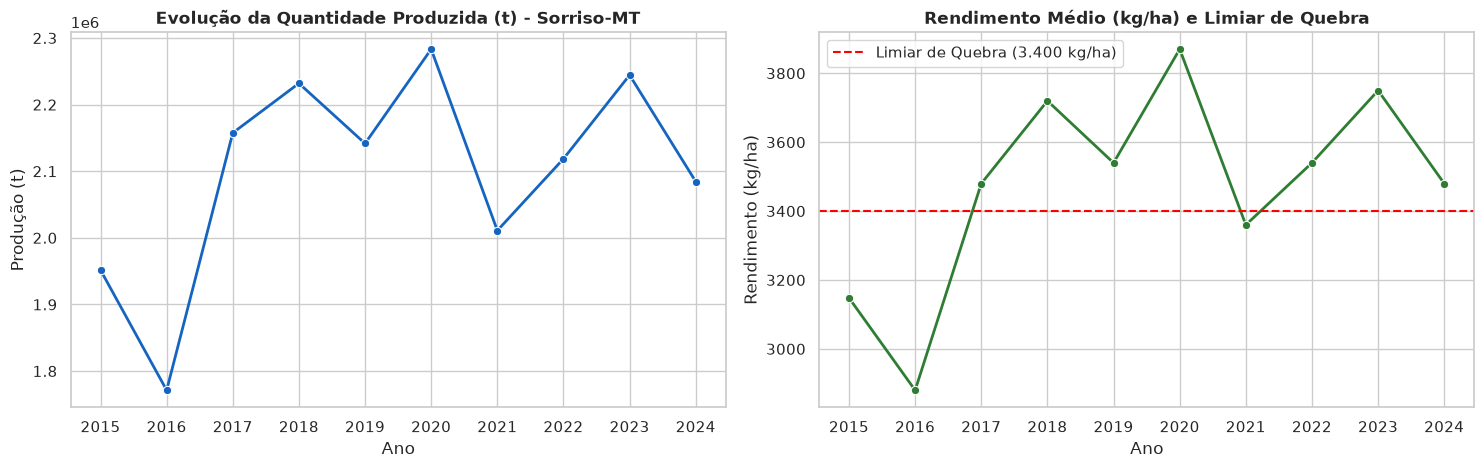

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Quantidade Produzida
sns.lineplot(data=df, x="ano", y="quantidade_produzida_t", marker="o", ax=axes[0], color="#1565c0", linewidth=2)
axes[0].set_title("Evolução da Quantidade Produzida (t) - Sorriso-MT", fontweight="bold")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Produção (t)")
axes[0].set_xticks(df["ano"].astype(int))

# 2. Rendimento com Linha de Limiar de Quebra
sns.lineplot(data=df, x="ano", y="rendimento_kg_ha", marker="o", ax=axes[1], color="#2e7d32", linewidth=2)
axes[1].axhline(3400, color="red", linestyle="--", linewidth=1.5, label="Limiar de Quebra (3.400 kg/ha)")
axes[1].set_title("Rendimento Médio (kg/ha) e Limiar de Quebra", fontweight="bold")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Rendimento (kg/ha)")
axes[1].set_xticks(df["ano"].astype(int))
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Dinâmica Agroclimática e Balanço Hídrico

/tmp/ipykernel_107855/2200715625.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="ano", y="PRECTOTCORR", ax=axes[0], palette="Blues_d")


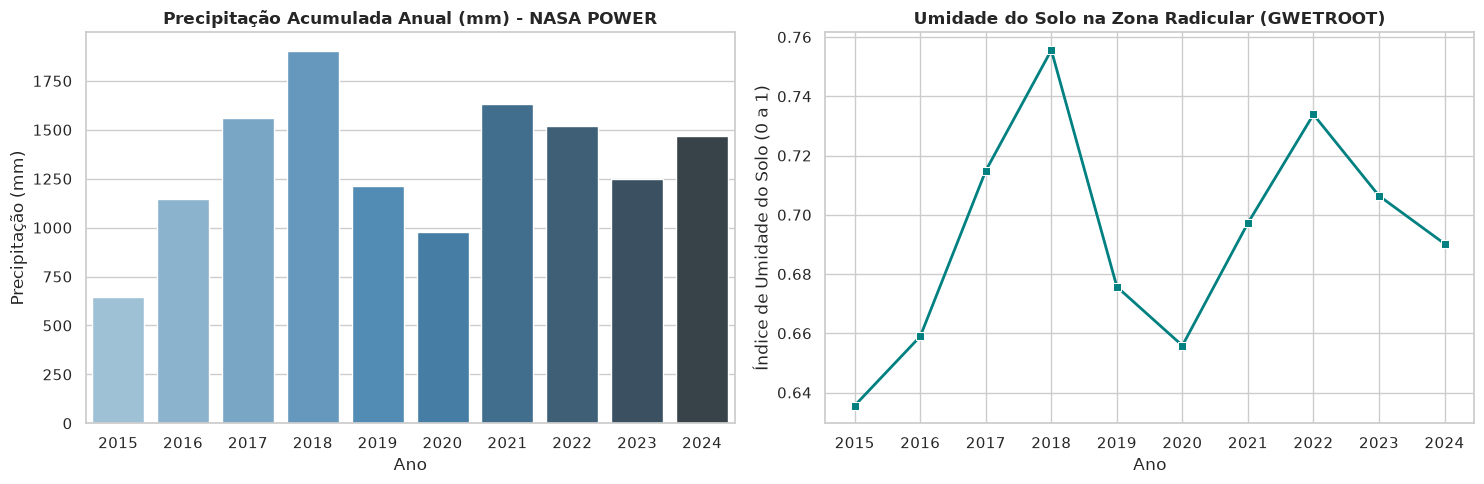

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Precipitação
sns.barplot(data=df, x="ano", y="PRECTOTCORR", ax=axes[0], palette="Blues_d")
axes[0].set_title("Precipitação Acumulada Anual (mm) - NASA POWER", fontweight="bold")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Precipitação (mm)")

# Umidade do Solo na Raiz
sns.lineplot(data=df, x="ano", y="GWETROOT", ax=axes[1], marker="s", color="teal", linewidth=2)
axes[1].set_title("Umidade do Solo na Zona Radicular (GWETROOT)", fontweight="bold")
axes[1].set_xlabel("Ano")
axes[1].set_ylabel("Índice de Umidade do Solo (0 a 1)")
axes[1].set_xticks(df["ano"].astype(int))

plt.tight_layout()
plt.show()

## 4. Análise da Variável-Alvo (`quebra_safra`) e Correlação com Features

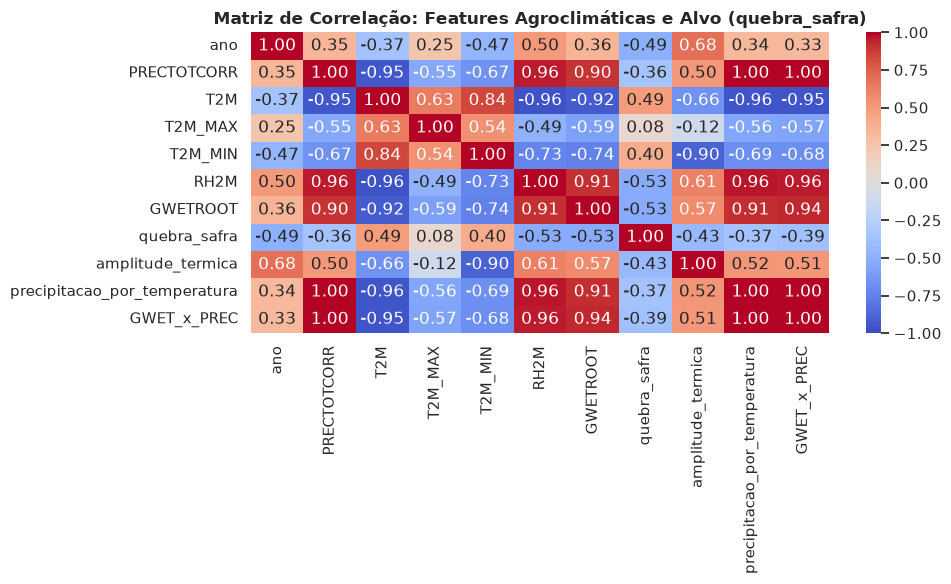

=== Distribuição Final da Variável-Alvo ===
quebra_safra
Safra Normal (0)       7
Quebra de Safra (1)    3
Name: count, dtype: int64

Percentual:
quebra_safra
0    70.0
1    30.0
Name: proportion, dtype: float64


In [5]:
plt.figure(figsize=(10, 6))
corr_matrix = df_feat.corr()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlação: Features Agroclimáticas e Alvo (quebra_safra)", fontweight="bold")
plt.tight_layout()
plt.show()

print("=== Distribuição Final da Variável-Alvo ===")
print(df_feat["quebra_safra"].value_counts().rename({0: "Safra Normal (0)", 1: "Quebra de Safra (1)"}))
print("\nPercentual:")
print(df_feat["quebra_safra"].value_counts(normalize=True) * 100)